# Step 7 – Backtesting and evaluation

Plan reference: `schneider_problem1_plan.md`, Step 7. The logic is in `src/`:

| Module | Role |
|---|---|
| `src/evaluation.py` | metric and jury tables, calibration tests, sub-periods, BOM-index backtest, compute / CO₂, sensitivity checks |
| `src/evaluation_plots.py` | charts (saved in `plots/step7/`) |
| `tests/test_evaluation.py` | formula tests (synthetic data) + leakage tests for the BOM model, the sliding window and the causal tuning |

**Reproduce** (from the repo root, after the Step 6 pipeline):

```bash
uv run python -m src.evaluation                              # Phases A–C tables and charts (~1.5 min)
uv run python -m src.evaluation --sensitivity                # + Phase D: sliding window, causal tuning
uv run --extra chronos python -m src.evaluation --compute    # + run time and CO₂ of every model (~4 min)
uv run pytest tests/test_evaluation.py                       # 14 tests
```

This notebook **reads the saved tables** in `report/problem1/step7_tables/`, so it runs in seconds. Set `RERUN = True` to recompute them.

**Step 7 evaluates; it chooses nothing.** The final model (`conformal_combo`) was fixed in Step 6 and the hold-out is frozen. Step 7 reads the Step 6 predictions and never writes into `Data/processed/models/`.

In [1]:
import os, subprocess, sys, warnings
warnings.filterwarnings("ignore")
from pathlib import Path
if Path.cwd().name == "analysis":
    os.chdir("..")
import numpy as np
import pandas as pd
from IPython.display import Image, display

from src import evaluation as E, evaluation_plots as EP
from src.feature_plots import TARGET_NAMES, set_style

pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 80)
set_style()

RERUN = False  # True: recompute every Step 7 table (needs the Step 6 predictions; ~5 min)
if RERUN:
    subprocess.run([sys.executable, "-m", "src.evaluation", "--sensitivity"], check=True)
T = EP.from_saved_tables(E.TABLE_DIR)
EP.make_all(T)
FINAL = E.FINAL_MODEL
print(f"{len(T)} tables loaded from {E.TABLE_DIR}")

16 tables loaded from /Users/kenzachaabouni/Documents/MSC_M2/shneider-electric/Schneider-Electric-Challenge/report/problem1/step7_tables


## 7.1 What Step 7 adds to Step 6

Step 6 already ran the rolling-origin backtest (expanding window, publication lags), froze and opened the hold-out once, chose the final model with the plan's rule, and produced the jury table on the hold-out. Step 7 completes the plan's evaluation:

| Plan Step 7 item | Where |
|---|---|
| MAPE, MASE, WAPE weighted by BOM € share, CRPS | 7.2–7.3 |
| Jury table on **both** windows, with CIs and Diebold–Mariano | 7.2 |
| Coverage with CIs, Kupiec / Christoffersen, PIT histogram | 7.4 |
| Sub-periods, stress windows, rolling loss plot | 7.5 |
| **BOM cost index** backtest | 7.6 |
| Compute and CO₂ per model | 7.7 |
| Sliding window, tuning without hindsight | 7.8 |
| Model selection and final refit | 7.9 |

**Windows** (by target month): **backtest** Feb 2022 → Mar 2025, where every choice was made; **hold-out** Apr 2025 → Sep 2026, opened once; **strict hold-out**, hold-out rows whose origin is from March 2025 on, so that no part of the outcome window was visible when choosing.

## 7.2 Does the final model beat the naive baseline?

Every forecast is matched with the random walk issued for the same target, horizon and origin. Skill = 1 − Σ loss / Σ loss of the random walk; 95 % CIs from a block bootstrap over origins (blocks of H months); Diebold–Mariano test with the Harvey–Leybourne–Newbold correction (one-sided p-value: "the model is better").

In [2]:
j = T["jury_table"]
cols = ["window", "horizon", "n_origins", "independent_windows", "pinball_skill", "pinball_skill_lo",
        "pinball_skill_hi", "dm_pinball_p_model_better", "mae_skill", "dm_mae_p_model_better", "mase",
        "coverage_80", "coverage_p90"]
display(j[j.model == FINAL][cols])
print("random walk MASE, same rows:")
display(j[j.model == "random_walk"][["window", "horizon", "mase"]].pivot(index="horizon", columns="window", values="mase"))

,window,horizon,n_origins,independent_windows,pinball_skill,pinball_skill_lo,pinball_skill_hi,dm_pinball_p_model_better,mae_skill,dm_mae_p_model_better,mase,coverage_80,coverage_p90
3,backtest,3,38,12.7,0.043,0.013,0.077,0.025,0.009,0.228,0.668,0.836,0.901
4,backtest,6,35,5.8,0.070,0.050,0.108,0.009,-0.017,0.971,0.780,0.865,0.967
5,backtest,9,32,3.6,0.107,0.078,0.139,0.006,-0.037,1.000,0.895,0.903,0.996
49,holdout,3,18,6.0,0.025,-0.009,0.053,0.102,0.016,0.064,0.965,0.837,0.856
50,holdout,6,18,3.0,-0.005,-0.058,0.060,0.539,0.011,0.316,1.106,0.796,0.815
51,holdout,9,18,2.0,0.008,-0.039,0.085,0.446,0.011,0.351,1.161,0.819,0.837
95,holdout_strict,3,16,5.3,0.025,-0.012,0.054,0.139,0.021,0.005,0.994,0.833,0.846
96,holdout_strict,6,13,2.2,-0.020,-0.067,0.025,0.665,0.021,0.065,1.325,0.718,0.744
97,holdout_strict,9,10,1.1,-0.032,NaN,NaN,NaN,0.022,NaN,1.725,0.687,0.707


random walk MASE, same rows:


window,backtest,holdout,holdout_strict
horizon,,,
3,0.672,0.989,1.024
6,0.762,1.121,1.356
9,0.866,1.174,1.765


- **Backtest:** the final model beats the random walk at every horizon on pinball loss, significantly (Diebold–Mariano p ≤ 0.025), but **not on the median**: its MAE is slightly worse at 6–9 months. The gain comes from the band.
- **Hold-out:** no horizon is significantly different from the random walk. The model **honestly matches** the naive baseline (Level 2 of the brief), slightly ahead at 3 months.
- **MASE** is above 1 on the hold-out **for the random walk too**: the 2025–26 copper rally moved prices more than history did. MASE < 1 means "smaller errors than the naive's usual historical error", not "beats the naive on these months"; that is the MAE skill.

**By material group** (hold-out):

In [3]:
g = T["metrics_by_group"]
show = g[(g.model.isin([FINAL, "random_walk"])) & (g.window == "holdout")]
display(show.pivot_table(index=["group", "horizon"], columns="model",
                         values=["pinball_skill", "mae_skill", "mape_pct", "coverage_80", "width_80_pct"]).round(3))

coverage_80                   mae_skill                    mape_pct               pinball_skill                width_80_pct            
model          conformal_combo random_walk conformal_combo random_walk conformal_combo random_walk conformal_combo random_walk conformal_combo random_walk
group  horizon                                                                                                                                            
epoxy  3                 0.833       0.833          -0.004         0.0           3.070       3.054          -0.052         0.0          12.005      14.380
       6                 0.722       1.000          -0.002         0.0           4.746       4.726           0.040         0.0          19.200      28.037
       9                 1.000       1.000          -0.020         0.0           5.686       5.544           0.170         0.0          25.196      36.841
market 3                 0.825       0.818           0.006         0.0           7.064       7.093           0.009         0.0          27.544      28.788
       6                 0.825       0.865           0.009         0.0          10.136      10.192          -0.023         0.0          40.467      41.500
       9                 0.825       0.913           0.014         0.0          11.602      11.727          -0.042         0.0          50.606      52.797
ppi    3                 0.849       0.841           0.036         0.0           4.021       4.163           0.061         0.0          12.195      15.414
       6                 0.778       0.889           0.017         0.0           6.142       6.224           0.020         0.0          19.349      26.499
       9                 0.786       0.960           0.008         0.0           6.884       6.910           0.068         0.0          26.543      39.276

## 7.3 Errors weighted by each product's recipe (WAPE)

Each material's error is weighted by its € share in the Step 2 recipe: copper is 61 % of RM6, steel and stainless about 94 % of AirSeT (epoxy low). The random walk forecasts "no change", so its WAPE is 1 by construction and the WAPE skill is 1 − WAPE.

In [4]:
display(E.bom_weights().pivot(index="target", columns="product", values="weight").round(3))
w = T["wape_by_product"]
display(w[w.model == FINAL].pivot_table(index=["product", "window"], columns="horizon", values="wape_skill").round(3))

product,AirSeT epoxy high,AirSeT epoxy low,RM6
target,,,
D01,NaN,NaN,0.613
D02,0.015,0.024,0.018
EPOXY_EUR,0.425,0.033,0.010
S09,0.561,0.943,0.337
S10,NaN,NaN,0.022


horizon                         3      6      9
product           window                       
AirSeT epoxy high backtest  0.024 -0.063 -0.073
                  holdout   0.034  0.001 -0.035
AirSeT epoxy low  backtest  0.042 -0.061 -0.076
                  holdout   0.068  0.004 -0.049
RM6               backtest  0.018 -0.028 -0.048
                  holdout   0.031  0.015  0.019

## 7.4 Calibration

Coverage of the 80 % band and share of outcomes below P90, with 95 % CIs:

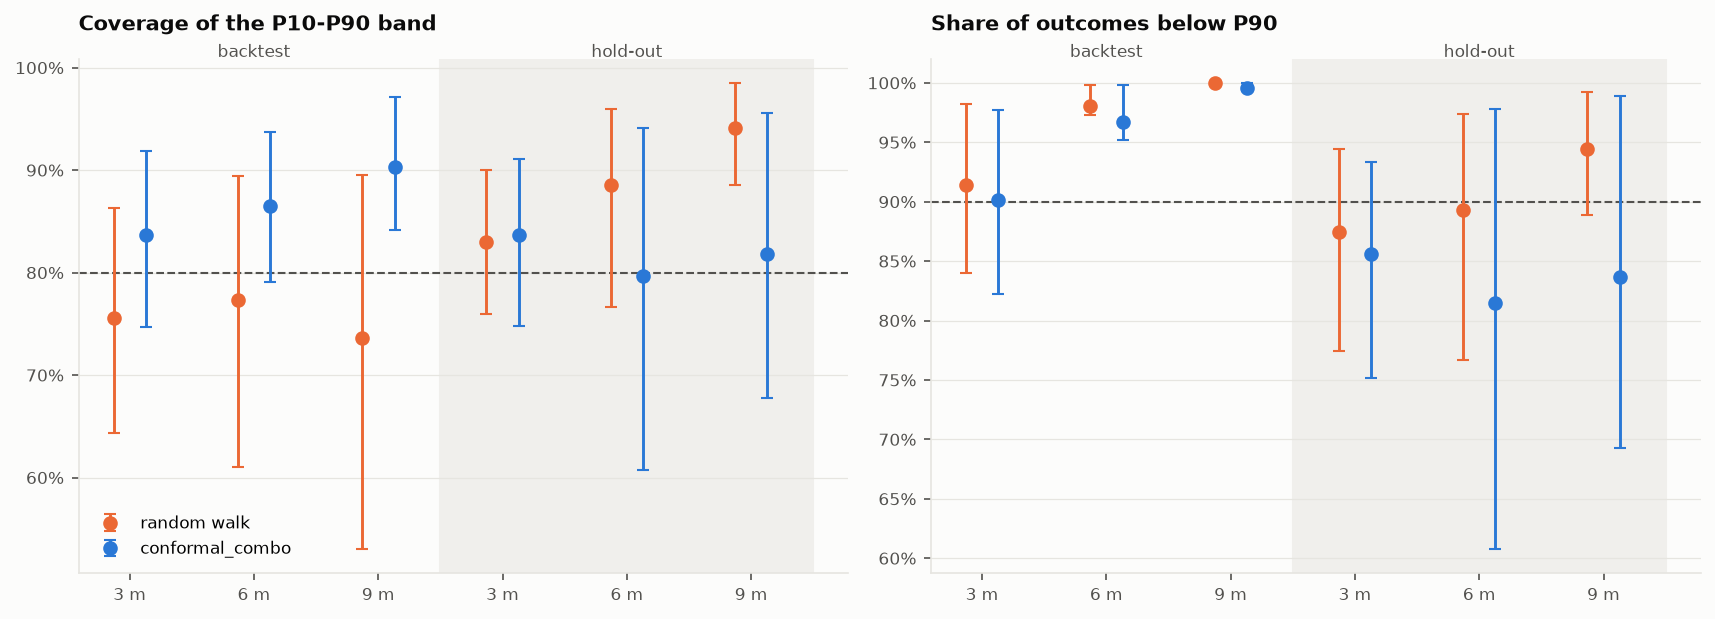

In [5]:
display(Image(EP.PLOT_DIR / "02_coverage_ci.png"))

**Kupiec** (is the miss rate right?) and **Christoffersen** (do misses cluster?) on non-overlapping origins (every H-th one; median over the H possible starting points). Misses of different materials at the same origin are correlated, so the p-values describe rather than prove.

In [6]:
ct = T["calibration_tests"]
display(ct[ct.model.isin([FINAL, "random_walk"])][["window", "model", "horizon", "miss", "target_rate", "miss_rate",
                                                     "kupiec_p", "miss_after_miss", "miss_after_hit", "christoffersen_p"]])

,window,model,horizon,miss,target_rate,miss_rate,kupiec_p,miss_after_miss,miss_after_hit,christoffersen_p
12,backtest,conformal_combo,3,P10-P90 band,0.2,0.164,1.930e-01,0.138,0.125,0.437
13,backtest,conformal_combo,3,above P90,0.1,0.099,8.103e-01,0.100,0.062,0.215
14,backtest,conformal_combo,6,P10-P90 band,0.2,0.135,1.968e-01,0.000,0.104,0.472
15,backtest,conformal_combo,6,above P90,0.1,0.033,2.300e-03,0.000,0.015,0.678
16,backtest,conformal_combo,9,P10-P90 band,0.2,0.097,4.770e-02,0.000,0.067,0.432
17,backtest,conformal_combo,9,above P90,0.1,0.004,2.300e-03,NaN,NaN,NaN
42,backtest,random_walk,3,P10-P90 band,0.2,0.245,4.920e-02,0.333,0.200,0.090
43,backtest,random_walk,3,above P90,0.1,0.086,6.835e-01,0.077,0.055,0.357
44,backtest,random_walk,6,P10-P90 band,0.2,0.227,7.929e-01,0.271,0.171,0.265
45,backtest,random_walk,6,above P90,0.1,0.020,6.000e-04,0.000,0.014,0.867


**Where outcomes fell** relative to the final model's quantiles (5 coarse bins; expected 10 / 40 / 40 / 5 / 5 %):

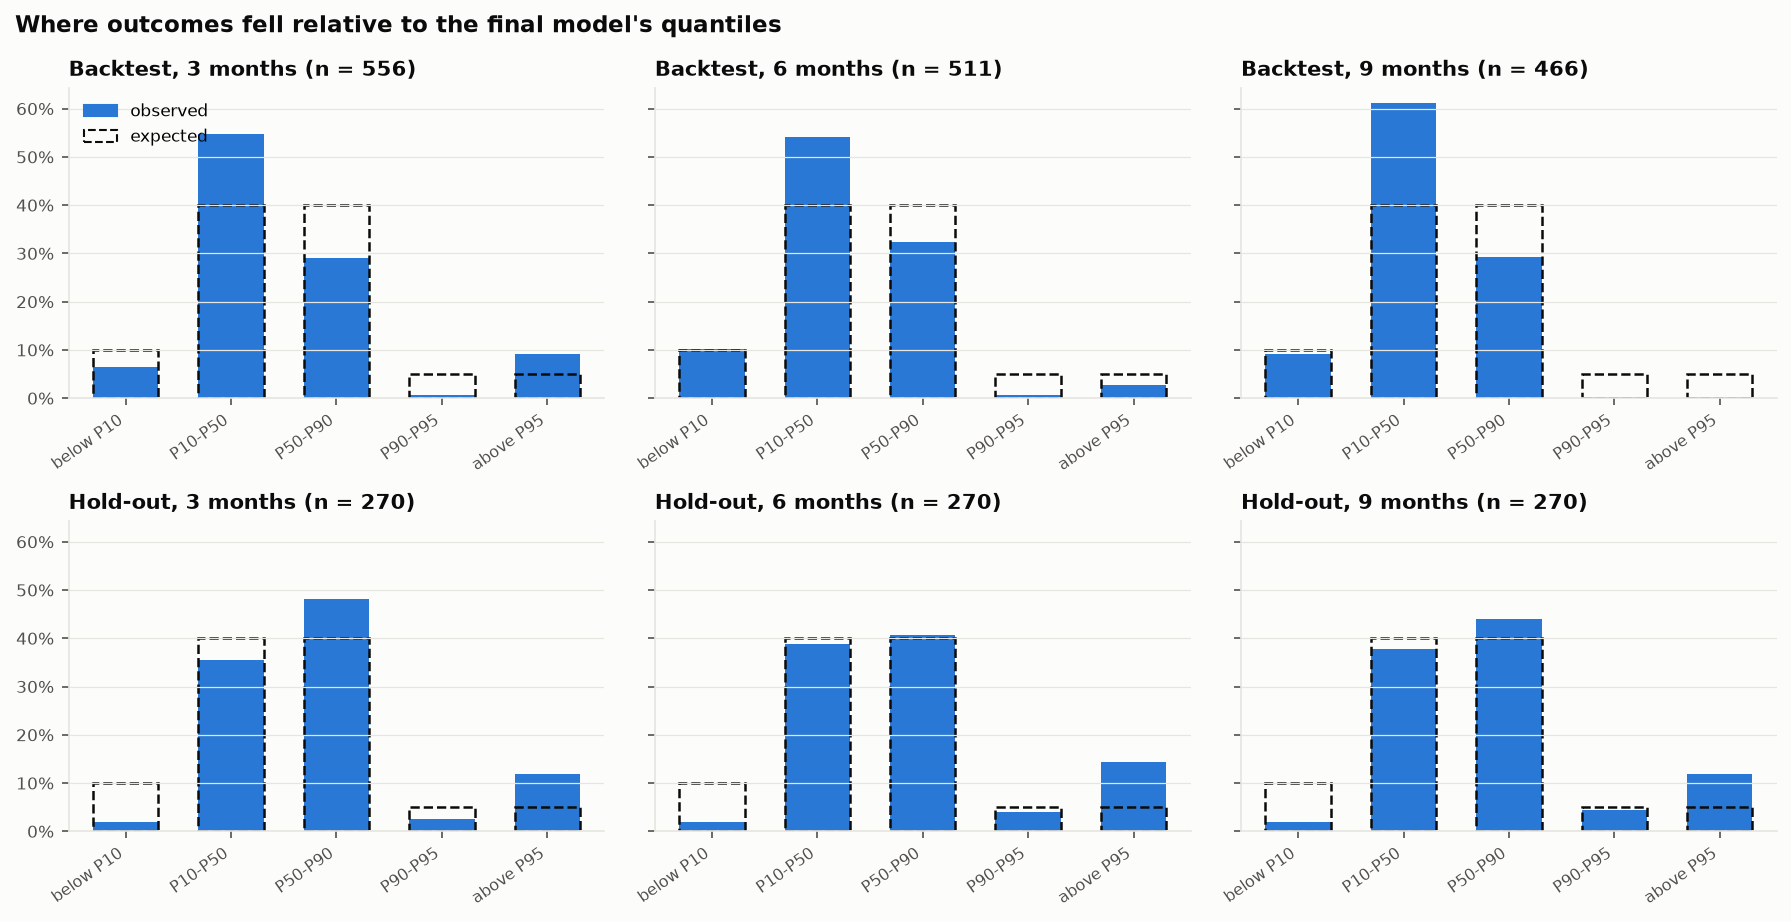

In [7]:
display(Image(EP.PLOT_DIR / "01_pit_histogram.png"))

- **The width of the band is right on average, but its centre follows the wrong regime.** On the backtest (prices mostly falling in 2023–24), 55–61 % of outcomes fell between P10 and P50 and almost none above P90 at 6–9 months (Kupiec p = 0.002): the upside band was too wide. On the hold-out (prices rising), only 2 % fell below P10 and 12–14 % above P95: the downside was too wide and the upside too narrow.
- **On the hold-out, 14–18 % of outcomes ended above P90** (target 10 %). With 2–6 independent windows, Kupiec cannot reject it (p = 0.10–0.26): low power, not proof of good calibration.
- **No sign that misses cluster** (Christoffersen p ≥ 0.19), on few misses.

## 7.5 Over time: sub-periods and stress windows

Describe, don't test: each sub-period has only a few independent H-month windows (column `independent_windows`).

,period,model,horizon,independent_windows,pinball_skill,mae_skill,coverage_80,coverage_p90
3,2022 (shock and peak),chronos_bolt,3,3.7,-0.043,-0.070,0.604,0.838
4,2022 (shock and peak),chronos_bolt,6,1.3,-0.145,-0.171,0.607,0.955
5,2022 (shock and peak),chronos_bolt,9,0.6,-0.043,-0.123,0.743,1.000
6,2022 (shock and peak),conformal_combo,3,3.7,0.056,0.017,0.675,0.786
7,2022 (shock and peak),conformal_combo,6,1.3,0.057,-0.019,0.661,0.884
8,2022 (shock and peak),conformal_combo,9,0.6,0.100,-0.029,0.743,0.971
18,2022 (shock and peak),gjr_fhs,3,3.7,0.006,0.000,0.630,0.753
19,2022 (shock and peak),gjr_fhs,6,1.3,0.076,0.000,0.714,0.893
20,2022 (shock and peak),gjr_fhs,9,0.6,0.086,0.000,0.714,0.971
21,2022 (shock and peak),random_walk,3,3.7,0.000,0.000,0.493,0.812


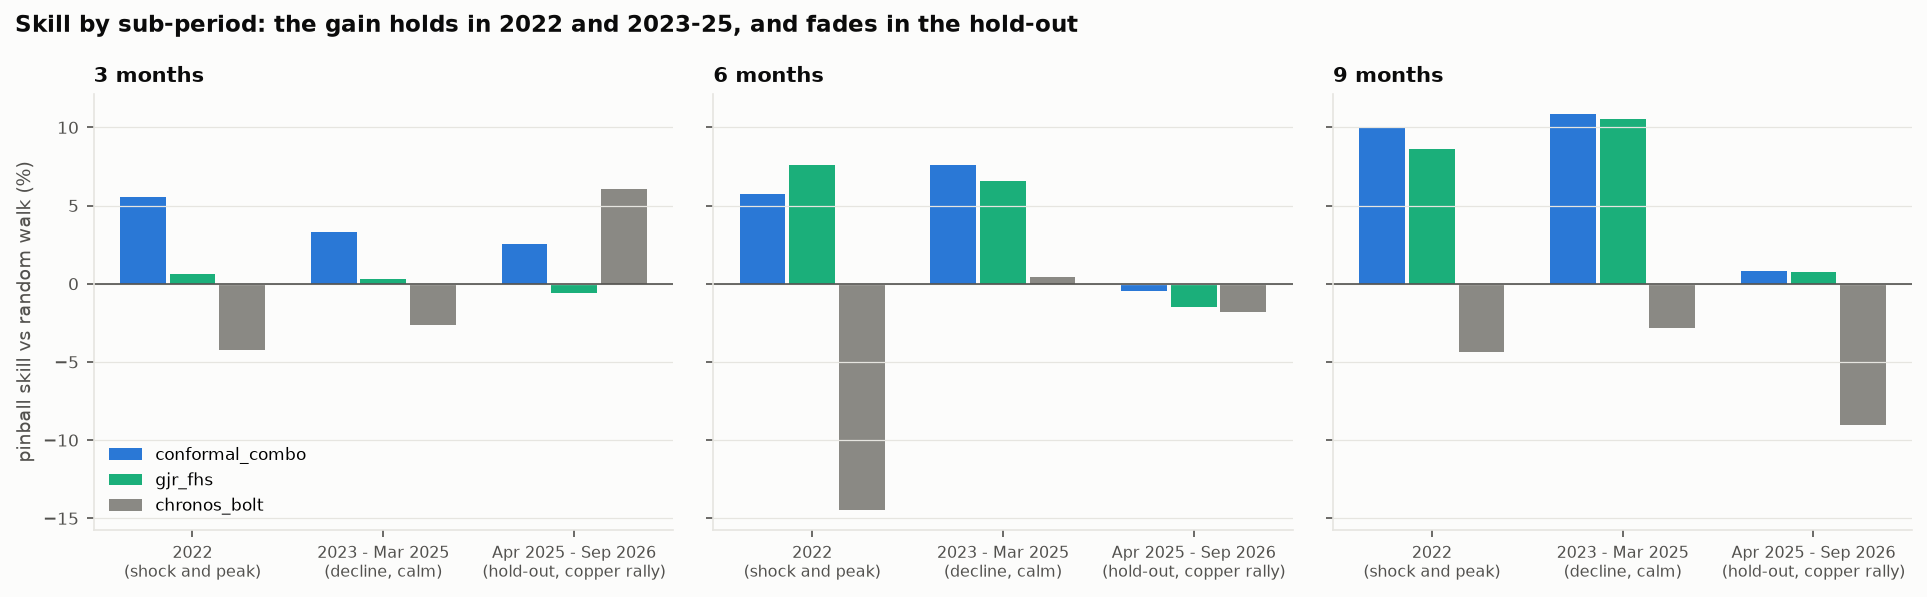

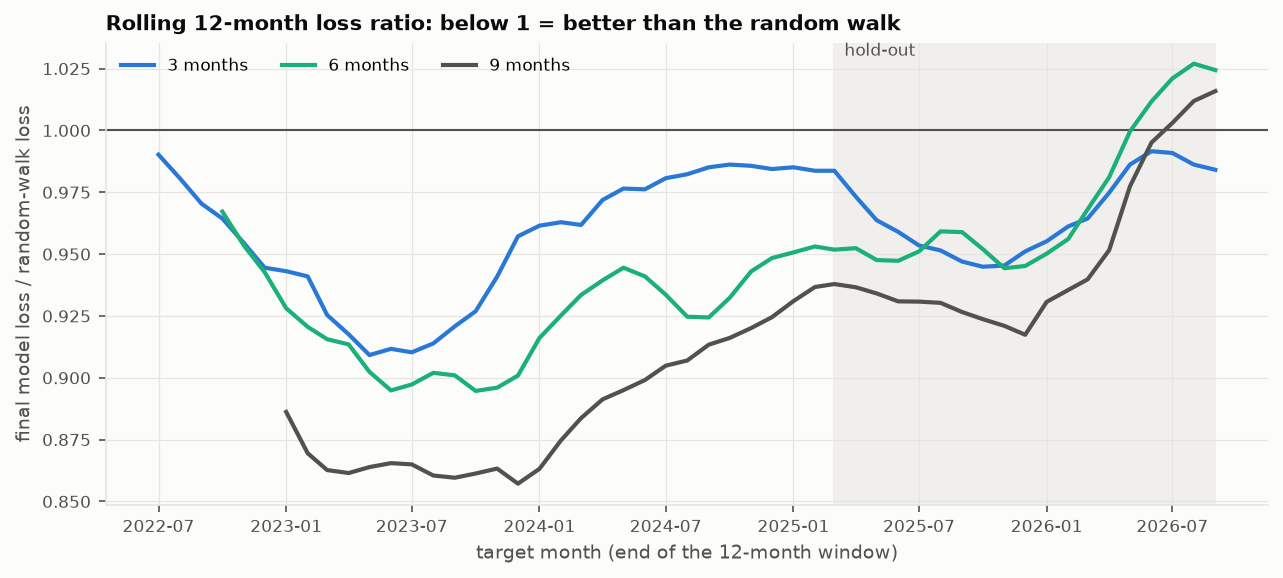

In [8]:
sp = T["subperiods"]
display(sp[sp.model.isin([FINAL, "random_walk", "gjr_fhs", "chronos_bolt"])]
        [["period", "model", "horizon", "independent_windows", "pinball_skill", "mae_skill", "coverage_80", "coverage_p90"]])
display(Image(EP.PLOT_DIR / "03_subperiod_skill.png"))
display(Image(EP.PLOT_DIR / "04_rolling_loss_ratio.png"))

- **The gain holds in both backtest periods** (2022 shock: +6 / +6 / +10 %; 2023 – Mar 2025: +3 / +8 / +11 %) and **fades in the hold-out** (+3 / −1 / +1 %). It is not a one-off from the 2022 shock.
- **Stress windows.** In the 2022 shock, bands were too narrow for everyone (final model 66–74 % coverage, random walk 49–63 %). In the 2025–26 rally, the final model's coverage was right (80–84 %) but its upper tail too short.
- **Rolling ratio:** the final model's loss was below the random walk's on every 12-month window until about April 2026; in the last months of the hold-out, the 6- and 9-month ratios rose to about 1.02–1.03. That is the copper rally.
- **Chronos** is the clearest example of instability: −14 % at 6 months in 2022, best model at 3 months on the hold-out.

## 7.6 BOM cost index backtest

The historical RM6 and AirSeT indices are built exactly as in Step 2 (fixed recipe, € weights at September 2026 prices) and forecast **directly** as their own series. They are added to the panel with a **2-month publication lag** (their slowest drivers), so they go through the same information sets, model code and leakage check as the materials. Models: the Step 5 baselines and the final model's own recipe (the four generalist members, equal weights, conformal γ frozen in Step 6). Nothing is re-chosen. The index starts in January 2018 (epoxy series), so there are 18–24 backtest origins.

,product,window,horizon,independent_windows,pinball_skill,pinball_skill_lo,pinball_skill_hi,mae_skill,coverage_80,coverage_p90
3,AirSeT epoxy high,backtest,3,8.0,0.182,0.116,0.269,-0.079,0.875,1.000
4,AirSeT epoxy high,backtest,6,3.5,0.216,0.157,0.306,-0.086,1.000,1.000
5,AirSeT epoxy high,backtest,9,2.0,0.179,0.141,0.243,-0.182,1.000,1.000
27,AirSeT epoxy high,holdout,3,6.0,0.154,-0.033,0.366,-0.017,0.833,0.833
28,AirSeT epoxy high,holdout,6,3.0,0.296,0.251,0.373,-0.022,0.944,0.944
29,AirSeT epoxy high,holdout,9,2.0,0.312,0.310,0.355,-0.042,1.000,1.000
51,AirSeT epoxy high,holdout_strict,3,5.3,0.134,-0.060,0.361,-0.006,0.812,0.812
52,AirSeT epoxy high,holdout_strict,6,2.2,0.284,0.232,0.388,0.008,0.923,0.923
53,AirSeT epoxy high,holdout_strict,9,1.1,0.318,NaN,NaN,0.029,1.000,1.000
75,AirSeT epoxy low,backtest,3,8.0,0.057,-0.057,0.206,-0.128,0.792,1.000


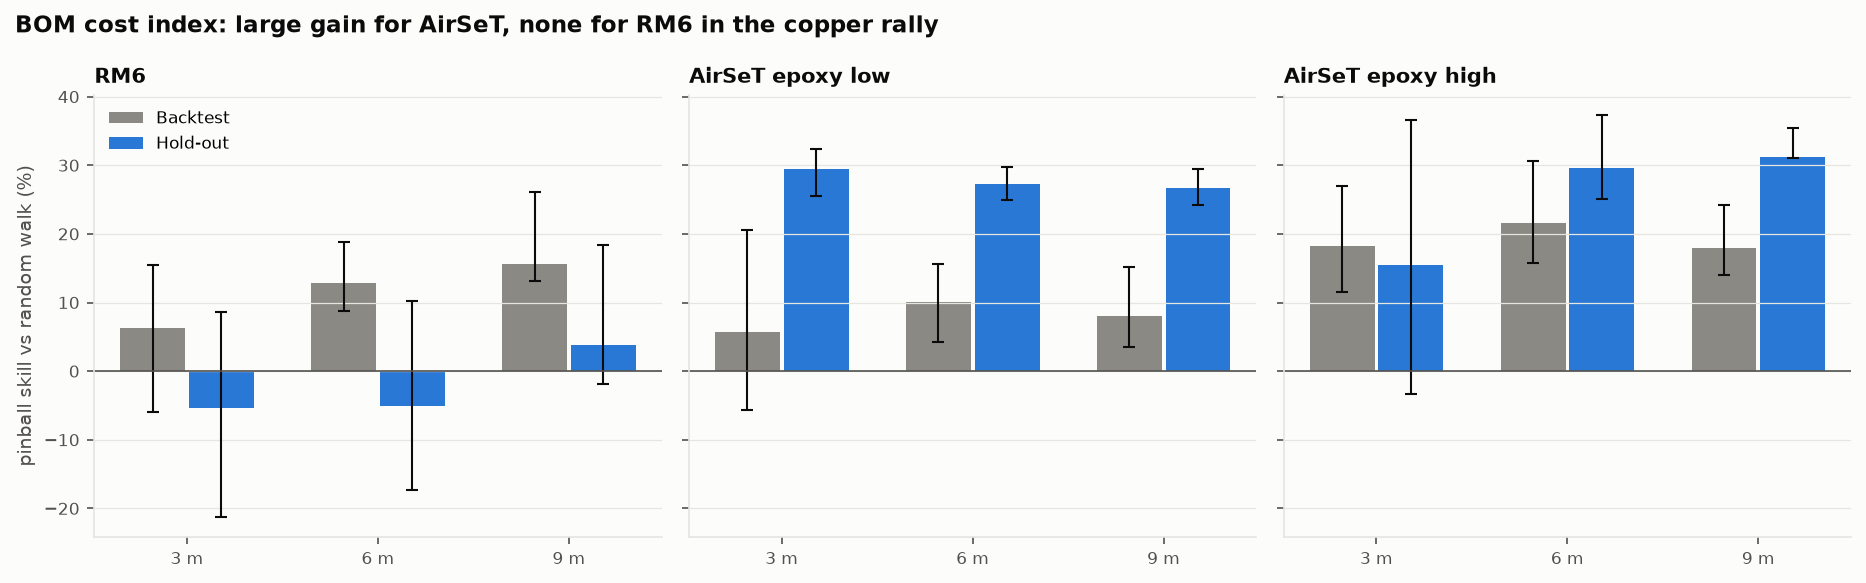

,product,horizon,index_p10,index_p50,index_p90
3282,AirSeT epoxy high,3,96.1,100.2,106.4
3322,AirSeT epoxy high,6,94.4,100.3,111.9
3359,AirSeT epoxy high,9,92.1,100.4,117.8
3402,AirSeT epoxy low,3,97.5,100.2,107.2
3442,AirSeT epoxy low,6,95.6,100.3,112.5
3479,AirSeT epoxy low,9,94.2,100.5,117.7
3522,RM6,3,92.7,100.2,104.7
3562,RM6,6,92.1,100.5,112.2
3599,RM6,9,88.8,100.7,118.2


In [9]:
bj = T["bom_jury_table"]
display(bj[bj.model == FINAL][["product", "window", "horizon", "independent_windows", "pinball_skill",
                               "pinball_skill_lo", "pinball_skill_hi", "mae_skill", "coverage_80", "coverage_p90"]])
display(Image(EP.PLOT_DIR / "05_bom_skill.png"))
bp = pd.read_csv(E.EVAL_DIR / "bom_predictions.csv", parse_dates=["origin"])
live = bp[(bp.model == FINAL) & (bp.origin == bp.origin.max())]
display(live.assign(index_p10=100 * np.exp(live.p10), index_p50=100 * np.exp(live.p50), index_p90=100 * np.exp(live.p90))
        [["product", "horizon", "index_p10", "index_p50", "index_p90"]].round(1))

- **AirSeT: a large gain** on the hold-out (+27 to +31 %). The random walk's band, built from history that includes the 2021 steel surge, was far too wide for the calm 2025–26 steel market (100 % coverage); the final model's bands are much narrower and still cover. For pricing: a much smaller buffer for AirSeT.
- **RM6: no gain in the copper rally.** The RM6 index ended above its P90 in 22 % of hold-out cases (target 10 %), and the final model is slightly worse than the random walk at 3–6 months. RM6 needs a **copper indexation clause**, not only a buffer.
- The real BOM rows of the CSV come from the Step 8 joint simulation; this is a direct check of the same target. Backtesting the Step 8 simulation itself needs it as a function of the origin (requested from Step 8).

## 7.7 Compute and CO₂

One full backtest of every model (all targets, horizons and origins), timed from scratch on a MacBook Pro 13" (2022, Mac14,7) with an Apple M2 chip: 8-core CPU (4 performance + 4 efficiency cores), 10-core GPU, 8 GB unified memory. Every model runs on the CPU only (Chronos included, `chronos_device = "cpu"`); the GPU is not used. Energy = run time × 20 W; CO₂ = energy × grid intensity (France ≈ 50 g/kWh, EU average ≈ 250 g/kWh). An estimate, with the assumptions in `compute_footprint`.

,model,approach,forecasts,wall_seconds,ms_per_forecast,energy_wh,co2_g_france,co2_g_eu_average
0,Step 5 baselines (all 5),direct,9780.0,8.470,0.866,0.047,0.002,0.012
1,ewma_fhs,direct,2388.0,2.484,1.040,0.014,0.001,0.004
2,garch_fhs,direct,2388.0,11.101,4.649,0.062,0.003,0.015
3,gjr_fhs,direct,2388.0,13.940,5.837,0.077,0.004,0.019
4,features_scaled,direct,913.0,4.198,4.598,0.023,0.001,0.006
5,auto_ets,recursive,2388.0,4.566,1.912,0.025,0.001,0.006
6,auto_arima,recursive,2388.0,51.159,21.423,0.284,0.014,0.071
7,auto_theta,recursive,2388.0,2.794,1.170,0.016,0.001,0.004
8,chronos_bolt,direct,2388.0,16.106,6.744,0.090,0.004,0.022
9,pooled_qr,direct,2388.0,75.650,31.680,0.420,0.021,0.105


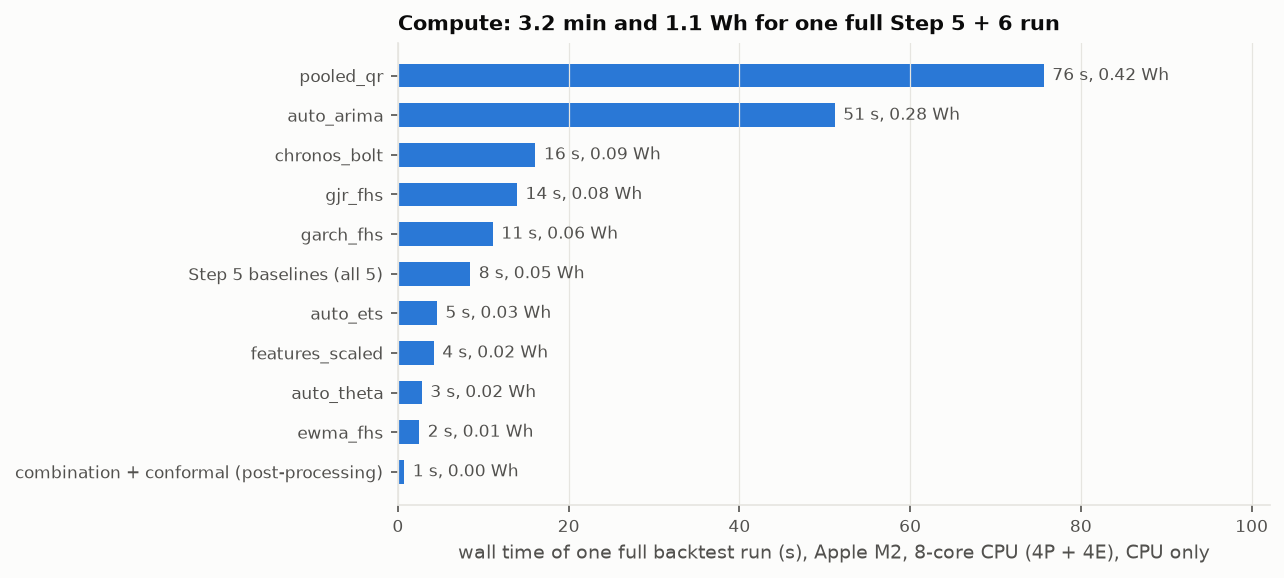

In [10]:
cf = T["compute_footprint"]
display(cf[["model", "approach", "forecasts", "wall_seconds", "ms_per_forecast", "energy_wh", "co2_g_france", "co2_g_eu_average"]].round(3))
display(Image(EP.PLOT_DIR / "07_compute.png"))

One full Step 5 + 6 run takes **3.2 minutes and about 1.1 Wh**: 0.05 g CO₂ on the French grid, 0.27 g on the EU average. The two slowest models (`pooled_qr`, `auto_arima`) are not in the final combination. The full leakage test suite (about 11 minutes) is about 3.7 Wh.

## 7.8 Sensitivity checks (reported, not acted on)

These could have changed Step 6 choices, but the hold-out is frozen, so they are checks, not re-choices.

**Sliding window (last 60 months) vs expanding**, for `ewma_fhs` and the historical quantiles (the plan: too short for GARCH and quantile regression):

In [11]:
sw = T["sliding_window"]
display(sw.pivot_table(index=["model"], columns=["window", "horizon"], values="pinball_skill").round(3))

window                     backtest               holdout              
horizon                           3      6      9       3      6      9
model                                                                  
ewma_fhs (expanding)          0.003  0.053  0.085  -0.005 -0.019 -0.005
ewma_fhs (last 60 m)         -0.014  0.039  0.079  -0.013 -0.058 -0.078
hist_quantiles (expanding)   -0.030 -0.071 -0.086   0.015 -0.016 -0.056
hist_quantiles (last 60 m)   -0.037 -0.078 -0.086   0.007 -0.071 -0.111

The expanding window wins on the backtest (where the plan says to choose) and on the hold-out: forgetting the 2021–22 shock made the bands too narrow for the 2025–26 rally. Step 6's choice is confirmed. (The two only differ from about November 2022: before that, the history is shorter than 60 months anyway.)

**Tuning without hindsight.** Step 6's choices (λ, members, the `features_scaled` rule, the conformal γ) re-made at every origin from the outcomes known at that origin only:

,window,model,mean_cell_skill,coverage_80,skill_3m,skill_6m,skill_9m
0,backtest,conformal_combo,0.085,0.866,0.043,0.070,1.067e-01
1,backtest,causal_combo,0.049,0.851,0.020,0.026,6.030e-02
2,holdout,conformal_combo,0.027,0.817,0.025,-0.005,8.100e-03
3,holdout,causal_combo,0.019,0.802,0.022,-0.012,1.000e-04


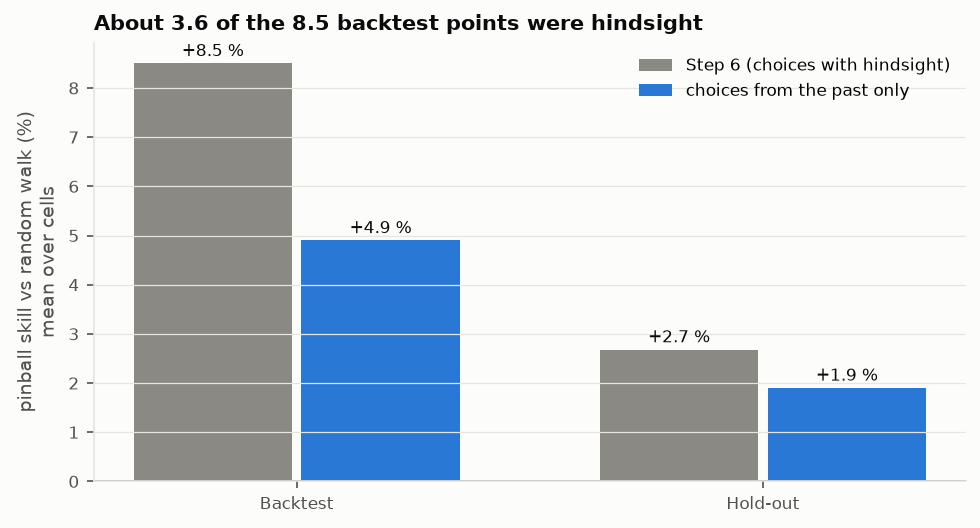

lambda chosen: {'lambda_ewma_fhs': {0.97: 53, 0.94: 4}, 'lambda_garch_fhs': {0.97: 53, 0.94: 4}, 'lambda_gjr_fhs': {0.97: 53, 0.94: 4}, 'lambda_features_scaled': {0.97: 31, 0.94: 26}}


,origin,known_3m_origins,members,gamma,note
0,2021-11-01,0,"auto_arima, auto_ets, auto_theta, chronos_bolt...",0.00,default (too few known outcomes)
8,2022-07-01,6,"auto_arima, auto_ets, auto_theta, chronos_bolt...",0.00,NaN
9,2022-08-01,7,"chronos_bolt, ewma_fhs@0.94, garch_fhs@0.94",0.00,NaN
11,2022-10-01,9,"ewma_fhs@0.94, garch_fhs@0.94",0.00,NaN
12,2022-11-01,10,"garch_fhs@0.97, pooled_qr",0.00,NaN
15,2023-02-01,13,"ewma_fhs@0.97, garch_fhs@0.97, pooled_qr",0.00,NaN
16,2023-03-01,14,"ewma_fhs@0.97, garch_fhs@0.97, gjr_fhs@0.97",0.00,NaN
19,2023-06-01,17,"ewma_fhs@0.97, features_scaled@0.94, garch_fhs...",0.00,NaN
23,2023-10-01,21,"ewma_fhs@0.97, features_scaled@0.97, garch_fhs...",0.00,NaN
39,2025-02-01,37,"auto_theta, ewma_fhs@0.97, features_scaled@0.9...",0.02,NaN


In [12]:
display(T["causal_vs_hindsight"])
display(Image(EP.PLOT_DIR / "06_causal_vs_hindsight.png"))
ch = T["causal_choices"]
print("lambda chosen:", {c: ch[c].value_counts().to_dict() for c in ch if c.startswith("lambda_")})
display(ch[["origin", "known_3m_origins", "members", "gamma", "note"]].drop_duplicates("members"))

- **About 3.6 of the 8.5 points of backtest skill were hindsight.** The honest backtest estimate of the method is **+4.9 %**, still clearly better than the random walk.
- **On the hold-out the two versions are close** (+1.9 % vs +2.7 %): the hold-out already gave the clean answer.
- **The procedure converges on Step 6's choices:** λ = 0.97 at 53 of 57 origins for the volatility models, unstable members during the 2022 shock, then from 2025 exactly Step 6's four members.

## 7.9 Model selection and final fit

**The rule (plan Step 7):** first keep the models whose coverage is acceptable, then pick the lowest pinball loss. Step 6 applied it on the backtest (`build_combination`): models forecasting every cell, coverage within 80 % ± 10, ranked by pinball skill; sizes 3 and 4 tried; then the `features_scaled` yes/no rule and the conformal calibration. Result: **`conformal_combo`** = `gjr_fhs` + `garch_fhs` + `ewma_fhs` + `auto_theta` (+ `features_scaled` in its 17 cells), γ = 0.02. Step 7 confirms the choice from two angles: re-made without hindsight at every origin, the same rule converges on the same members (7.8), and the sliding-window alternative is worse.

**Final fit.** The submission forecasts are the final model's rows at the **September 2026 origin**. They are already fitted on **all data known up to September 2026, including the hold-out months**: every model trains on all outcomes known at the origin, and the conformal factors have learnt from every outcome up to September 2026. The hold-out was used for evaluation only, not left out of the final fit. These rows are exported for Step 8 (`src.models --stage export`) and will be written to the CSV in Step 12.

## 7.10 Findings

1. **Beats naive?** Backtest: yes at every horizon on pinball loss, significant; hold-out: honestly matches at every horizon. Honest backtest estimate (without hindsight): +4.9 %.
2. **The value is in the band**, not the median: right coverage with narrower bands than the random walk for price indices and epoxy.
3. **The band's centre follows the wrong regime** (too wide upside in the 2023–24 decline, too short upside in the 2025–26 rally). Width is calibrated, direction is not forecastable.
4. **AirSeT's cost index is much better forecast than by the random walk** (+27 to +31 % on the hold-out); **RM6's is not**, because of copper.
5. **The gain is stable across 2022 and 2023–25** and fades in the hold-out.
6. **Compute is negligible:** 3.2 min and about 1 Wh per full run.

## 7.11 Limits

- **Small samples:** 18–38 origins per cell, overlapping: about 6 / 3 / 2 independent hold-out windows at 3 / 6 / 9 months. Tests have low power.
- **Correlated materials:** misses at the same origin are not independent, so calibration p-values are optimistic.
- **CRPS** is an approximation from P10 / P50 / P90 (levels 5–95 %); the exact CRPS of the BOM index needs the Step 8 simulated paths.
- **BOM index:** fixed recipe and € weights at September 2026 prices; history from 2018 only.
- **Compute:** an estimate (constant 20 W), not a power measurement.